# Atomic Charges and the Dipole Moment

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/temp/07-charges-dipole.ipynb)
:::


In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    sys.path.insert(0, "..")                    # psi4_helpers.py is one folder up
    plt.style.use("../styles/tufte.mplstyle")
    nproc = 4          # house limit: 4 threads

import psi4_helpers as ph

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
_ = psi4.set_memory("2 GB")


  Threads set to 4 by Python driver.



  Memory set to   1.863 GiB by Python driver.


Water is polar: oxygen pulls electron density away from the hydrogens. Two numbers describe this. The **dipole moment** is a real, measurable property of the whole molecule. **Atomic charges** are a way of dividing the electron density among the atoms, and there are many ways to do the dividing.

## What You Will Learn
- How to calculate the dipole moment and atomic charges with `psi4.oeprop()`.
- How three charge schemes (**Mulliken**, **Löwdin**, **MBIS**) differ.
- Why atomic charges depend strongly on the basis set while the dipole moment settles down.

The experimental dipole moment of water vapour is **1.855 D** (Clough *et al.*, *J. Chem. Phys.* **1973**, *59*, 2254).

In [2]:
psi4.set_output_file("output/07-charges-dipole.out", False);
psi4.set_options({"scf_type": "df"})
au2debye = psi4.constants.dipmom_au2debye
dipole_exp = 1.855

## 1. One Calculation in Detail

We use the experimental structure so that only the method and basis set change.

```{note} Psi4 settings in this cell
:class: dropdown
`psi4.oeprop(wfn, "DIPOLE", "MULLIKEN_CHARGES", "LOWDIN_CHARGES", "MBIS_CHARGES", title="HF")`
: Calculates **one-electron properties** from a finished wavefunction. The results are stored on the wavefunction, e.g. `wfn.variable("MULLIKEN CHARGES")`, and the dipole also as `wfn.variable("HF DIPOLE")` (the `title` sets the prefix). Other available properties include `QUADRUPOLE`, `WIBERG_LOWDIN_INDICES` and `MAYER_INDICES` (bond orders), and `GRID_ESP`.

Charge schemes
: **Mulliken** splits the density shared between two atoms equally. **Löwdin** first makes the basis functions orthogonal, then does the same. Both depend directly on the basis functions, so they change with the basis set. **MBIS** (minimal basis iterative stockholder) divides the density in real space, so it is much less sensitive to the basis set.
: *Alternatives:* **RESP** charges, fitted to reproduce the electrostatic potential, are standard for force fields; they need the `resp` add-on. **Natural (NBO)** charges are popular in organic chemistry but are not available in *Psi4*.

Dipole units
: *Psi4* reports dipoles in atomic units ($e\,a_0$). Multiply by `psi4.constants.dipmom_au2debye` (2.5417) to get debye.
```

In [3]:
water = psi4.geometry("""
0 1
O
H 1 0.9578
H 1 0.9578 2 104.48
""")

psi4.set_options({"basis": "cc-pvdz"})
E, wfn = psi4.energy("hf", molecule=water, return_wfn=True)
psi4.oeprop(wfn, "DIPOLE", "MULLIKEN_CHARGES", "LOWDIN_CHARGES", "MBIS_CHARGES", title="HF")

dipole = wfn.variable("HF DIPOLE")          # vector (x, y, z) in e a0
print("Dipole vector (D):", np.round(dipole * au2debye, 3))
print(f"Dipole magnitude: {np.linalg.norm(dipole) * au2debye:.3f} D")

charges = pd.DataFrame({
    "atom": [water.symbol(i) for i in range(water.natom())],
    "Mulliken": wfn.variable("MULLIKEN CHARGES"),
    "Löwdin": wfn.variable("LOWDIN CHARGES"),
    "MBIS": wfn.variable("MBIS CHARGES").flatten(),
})
charges.round(3)

Dipole vector (D): [0.    0.    2.058]
Dipole magnitude: 2.058 D


,atom,Mulliken,Löwdin,MBIS
0,O,-0.306,-0.095,-0.862
1,H,0.153,0.048,0.431
2,H,0.153,0.048,0.431


All three schemes agree that oxygen is negative and the hydrogens positive, and each set adds up to zero. But the size of the charge on oxygen differs by a factor of about ten between Löwdin and MBIS. There is no single "true" atomic charge: each scheme answers a slightly different question.

## 2. Changing the Basis Set and Method

Now we repeat the calculation with basis sets from minimal to large, using HF and B3LYP.

In [4]:
basis_sets = ["sto-3g", "6-31g", "6-31g*", "cc-pvdz", "aug-cc-pvdz", "aug-cc-pvtz"]
rows = []
for method in ["hf", "b3lyp"]:
    for basis in basis_sets:
        psi4.set_options({"basis": basis})
        E, w = psi4.energy(method, molecule=water, return_wfn=True)
        psi4.oeprop(w, "DIPOLE", "MULLIKEN_CHARGES", "LOWDIN_CHARGES", "MBIS_CHARGES", title=method.upper())
        rows.append({"method": method, "basis": basis,
                     "dipole (D)": np.linalg.norm(w.variable(f"{method.upper()} DIPOLE")) * au2debye,
                     "q(O) Mulliken": w.variable("MULLIKEN CHARGES")[0],
                     "q(O) Löwdin": w.variable("LOWDIN CHARGES")[0],
                     "q(O) MBIS": w.variable("MBIS CHARGES").flatten()[0]})

props = pd.DataFrame(rows)
props.round(3)

,method,basis,dipole (D),q(O) Mulliken,q(O) Löwdin,q(O) MBIS
0,hf,sto-3g,1.725,-0.366,-0.253,-0.589
1,hf,6-31g,2.631,-0.792,-0.582,-0.897
2,hf,6-31g*,2.226,-0.866,-0.712,-0.907
3,hf,cc-pvdz,2.058,-0.306,-0.095,-0.862
4,hf,aug-cc-pvdz,2.000,-0.299,0.192,-0.909
5,hf,aug-cc-pvtz,1.984,-0.439,1.033,-0.918
6,b3lyp,sto-3g,1.678,-0.368,-0.254,-0.579
7,b3lyp,6-31g,2.461,-0.706,-0.548,-0.838
8,b3lyp,6-31g*,2.079,-0.778,-0.676,-0.846
9,b3lyp,cc-pvdz,1.911,-0.255,-0.080,-0.793


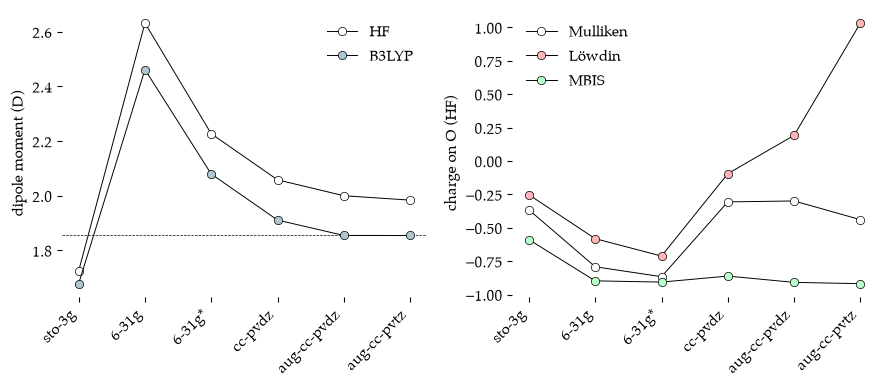

In [5]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9,4))
x = np.arange(len(basis_sets))
colors = {"hf": "white", "b3lyp": "#AEC6CF"}

for method in ["hf", "b3lyp"]:
    sub = props[props["method"] == method]
    axs[0].plot(x, sub["dipole (D)"], color="black", linewidth=0.7, marker="o",
                markerfacecolor=colors[method], markeredgecolor="black", markeredgewidth=0.5, label=method.upper())
axs[0].axhline(dipole_exp, color="black", linewidth=0.5, linestyle="--", zorder=1)
axs[0].set_ylabel("dipole moment (D)")
axs[0].legend()

sub = props[props["method"] == "hf"]
for col, color in [("q(O) Mulliken", "white"), ("q(O) Löwdin", "#FFB3BA"), ("q(O) MBIS", "#BAFFC9")]:
    axs[1].plot(x, sub[col], color="black", linewidth=0.7, marker="o",
                markerfacecolor=color, markeredgecolor="black", markeredgewidth=0.5, label=col[5:])
axs[1].set_ylabel("charge on O (HF)")
axs[1].legend()

for ax in axs:
    ax.set_xticks(x)
    ax.set_xticklabels(basis_sets, rotation=45, ha="right")
plt.tight_layout()
plt.show()

What the plots show:

- The **dipole moment** varies a lot with small basis sets but settles down with the large augmented sets. HF overestimates it (no electron correlation makes the bonds too ionic); B3LYP comes closer to 1.855 D. Diffuse functions (`aug-`) matter for the dipole because it depends on the outer, loosely held part of the density.
- **Mulliken** and **Löwdin** charges jump around and do not settle as the basis set grows. With the augmented basis sets the Löwdin charge on oxygen even becomes **positive**, which is chemically absurd. The diffuse functions on oxygen are so spread out that the scheme hands their electrons to the hydrogens. These charges are only useful for comparing molecules calculated with the **same**, modest basis set.
- **MBIS** charges change much less with the basis set.

```{tip} Which should you use?
Use the **dipole moment** (or the electrostatic potential in the *Surfaces* notebook) when you want to describe polarity. If you need atomic charges, choose one scheme and one basis set and keep them fixed, and prefer a density-based scheme such as MBIS.
```

## Summary
- `psi4.oeprop()` calculates the dipole moment, atomic charges and bond orders from a wavefunction.
- The dipole moment is an observable and converges with the basis set; diffuse functions are important.
- Atomic charges are a model; Mulliken and Löwdin charges are strongly basis-set dependent.